In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Load the customer churn dataset
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Future Interns - Task 2")
print("Customer Retention and Churn Analysis")

print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())


Future Interns - Task 2
Customer Retention and Churn Analysis

Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:

# Check the churn column
print("Churn values:")
print(df["Churn"].value_counts())

# Calculate the number of customers
total_customers = len(df)

# Count customers who left
churned_customers = (df["Churn"] == "Yes").sum()

# Calculate churn rate
churn_rate = (churned_customers / total_customers) * 100

print("\n===== CUSTOMER CHURN SUMMARY =====")
print("Total Customers:", total_customers)
print("Customers Who Left:", churned_customers)
print("Customers Who Stayed:", total_customers - churned_customers)
print(f"Churn Rate: {churn_rate:.2f}%")


Churn values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

===== CUSTOMER CHURN SUMMARY =====
Total Customers: 7043
Customers Who Left: 1869
Customers Who Stayed: 5174
Churn Rate: 26.54%


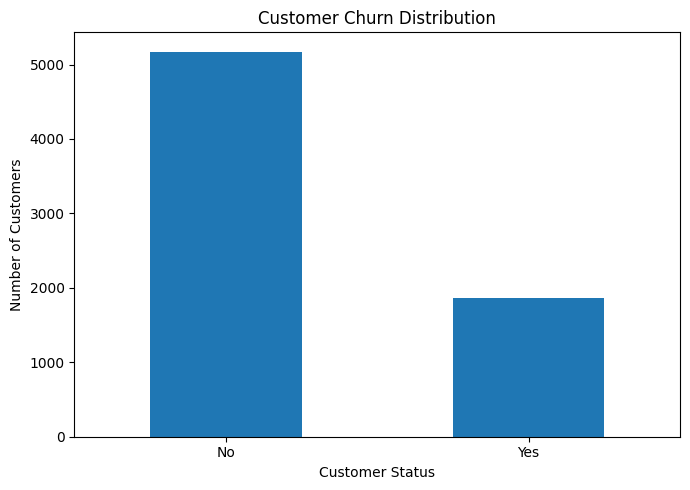

In [ ]:

# Count customers who stayed and left
churn_counts = df["Churn"].value_counts()

# Create a bar chart
plt.figure(figsize=(7, 5))
churn_counts.plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


===== CHURN RATE BY CONTRACT TYPE (%) =====


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


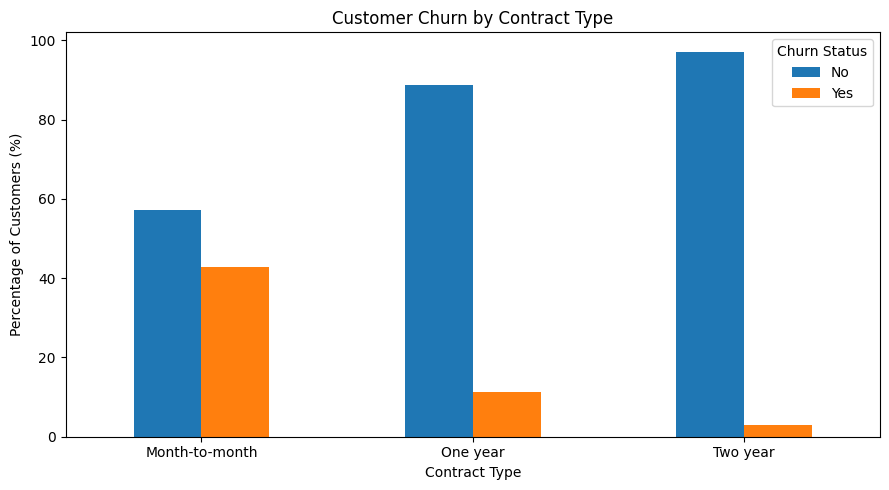

In [ ]:

# Calculate churn rate for each contract type
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print("===== CHURN RATE BY CONTRACT TYPE (%) =====")
display(contract_churn.round(2))

# Create a chart
contract_churn.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn Status")
plt.tight_layout()
plt.show()


===== CHURN BY CUSTOMER TENURE (%) =====


Churn,No,Yes
Tenure_Group,,
0-12 months,52.56,47.44
13-24 months,71.29,28.71
25-48 months,79.61,20.39
49-72 months,90.49,9.51


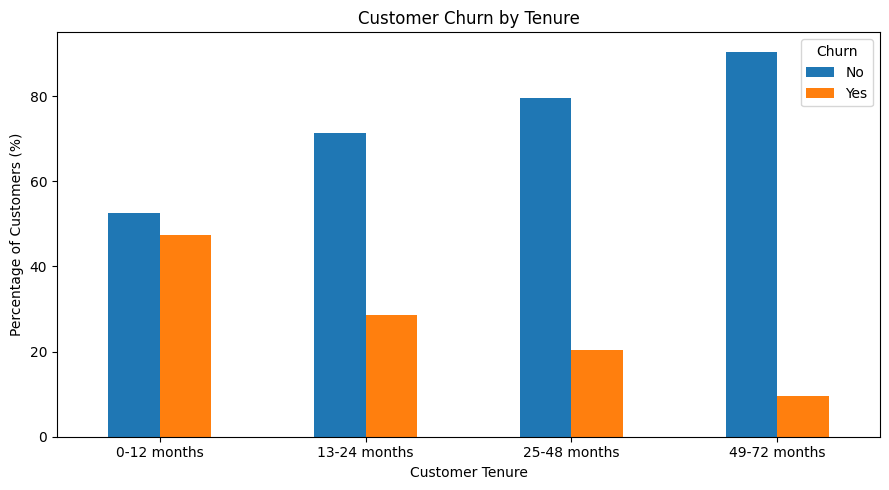

In [ ]:

# Group customers by tenure
df["Tenure_Group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months",
            "25-48 months", "49-72 months"]
)

# Calculate churn percentage by tenure group
tenure_churn = pd.crosstab(
    df["Tenure_Group"],
    df["Churn"],
    normalize="index"
) * 100

print("===== CHURN BY CUSTOMER TENURE (%) =====")
display(tenure_churn.round(2))

tenure_churn.plot(kind="bar", figsize=(9, 5))

plt.title("Customer Churn by Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


===== MONTHLY CHARGES BY CHURN STATUS =====


,mean,median,count
Churn,,,
No,61.27,64.43,5174
Yes,74.44,79.65,1869


<Figure size 800x500 with 0 Axes>

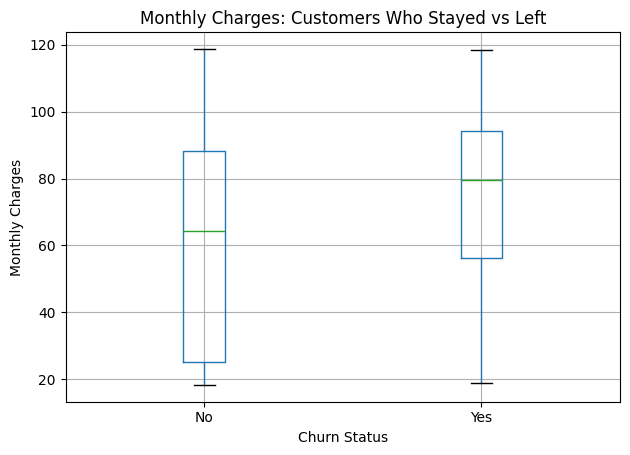

In [ ]:

# Compare monthly charges for customers who stayed and left
charges_summary = df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median", "count"]
)

print("===== MONTHLY CHARGES BY CHURN STATUS =====")
display(charges_summary.round(2))

# Create a box plot
plt.figure(figsize=(8, 5))

df.boxplot(
    column="MonthlyCharges",
    by="Churn"
)

plt.title("Monthly Charges: Customers Who Stayed vs Left")
plt.suptitle("")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()


In [ ]:

# Compare churn rates across customer groups
for column in ["Contract", "InternetService", "PaymentMethod"]:
    churn_summary = (
        df.groupby(column, observed=True)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    print(f"\n===== CHURN RATE BY {column.upper()} (%) =====")
    display(churn_summary.round(2).rename("Churn Rate (%)").reset_index())



===== CHURN RATE BY CONTRACT (%) =====


,Contract,Churn Rate (%)
0,Month-to-month,42.71
1,One year,11.27
2,Two year,2.83



===== CHURN RATE BY INTERNETSERVICE (%) =====


,InternetService,Churn Rate (%)
0,Fiber optic,41.89
1,DSL,18.96
2,No,7.40



===== CHURN RATE BY PAYMENTMETHOD (%) =====


,PaymentMethod,Churn Rate (%)
0,Electronic check,45.29
1,Mailed check,19.11
2,Bank transfer (automatic),16.71
3,Credit card (automatic),15.24


 CUSTOMER RETENTION & CHURN DASHBOARD
Total Customers : 7,043
Customers Churned: 1,869
Customers Retained: 5,174
Churn Rate       : 26.54%
Retention Rate   : 73.46%


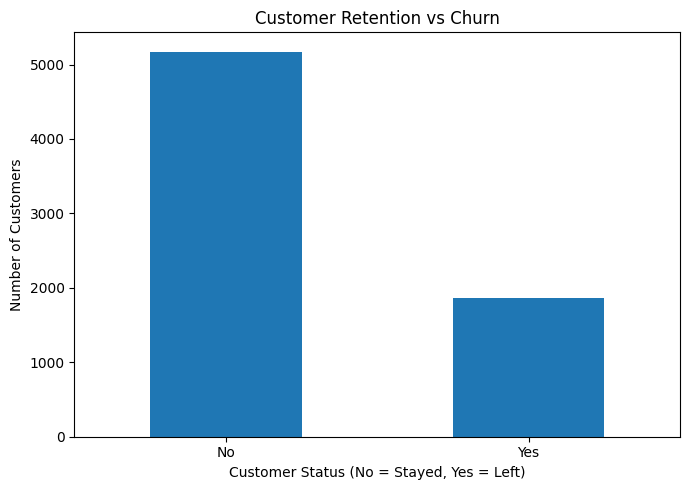

In [ ]:

# Customer churn dashboard

total_customers = len(df)
churned = (df["Churn"] == "Yes").sum()
retained = (df["Churn"] == "No").sum()
churn_rate = churned / total_customers * 100
retention_rate = retained / total_customers * 100

print("=" * 45)
print(" CUSTOMER RETENTION & CHURN DASHBOARD")
print("=" * 45)
print(f"Total Customers : {total_customers:,}")
print(f"Customers Churned: {churned:,}")
print(f"Customers Retained: {retained:,}")
print(f"Churn Rate       : {churn_rate:.2f}%")
print(f"Retention Rate   : {retention_rate:.2f}%")

# Visualize customer status
plt.figure(figsize=(7, 5))
df["Churn"].value_counts().reindex(["No", "Yes"]).plot(
    kind="bar"
)
plt.title("Customer Retention vs Churn")
plt.xlabel("Customer Status (No = Stayed, Yes = Left)")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Customer Retention Recommendations

1. **Improve early customer support:** Review the experience of new customers and help them resolve setup or service issues quickly.
2. **Review contract patterns:** Compare churn across month-to-month and longer-term contracts before designing retention offers.
3. **Evaluate pricing and value:** Investigate whether monthly charges, service quality, or customer expectations are associated with churn.
4. **Monitor payment experience:** Examine churn by payment method and identify avoidable billing difficulties.
5. **Track churn regularly:** Monitor churn and retention rates over time to measure whether retention strategies work.

**Important:** These are recommendations to investigate. Final conclusions should be based on the actual analysis results, not assumptions about why customers leave.
